# City of Austin Procurement Analysis (Fiscal Year 2023)

**Goal:** Analyse the City of Austin's goods purchases in fiscal year 2023 (1 October 2022 – 30 September 2023) and answer three business questions:

1. **Supplier concentration:** Is spend concentrated in a few suppliers?
2. **Timing:** How is spend distributed across the year? Is there a spike at fiscal year-end?
3. **Master agreement coverage:** How much of the spend is tied to master agreements?

**Data:** *Purchase Order Quantity Price detail for Commodity/Goods procurements* from the City of Austin Open Data Portal. Each row is one line item of a purchase order.

**Tools:** pandas (reading, filtering, grouping, dates) and matplotlib (simple charts).

## 1. Setup

- `pandas`: to read and work with tabular data.
- `matplotlib`: to draw charts.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Make tables easier to read: show all columns, print decimals with 2 digits
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

## 2. Loading the data

The `commodity` (product code), `vendor_code` (supplier code) and `zip` (postal code) columns look like numbers, but they are really **labels**. Some codes start with 0 (e.g. `0801560`). If pandas read them as numbers, the leading zero would be lost. That is why these three columns are read as text (`str`).

In [2]:
df = pd.read_csv(
    "data/austin_purchase_orders_fy2023.csv",
    dtype={"commodity": str, "vendor_code": str, "zip": str},
)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Rows: 10699
Columns: 21


,commodity,commodity_description,extended_description,quantity,unit_of_measure,unit_of_meas_desc,unit_price,itm_tot_am,master_agreement,contract_name,purchase_order,award_date,vendor_code,lgl_nm,ad_ln_1,ad_ln_2,city,st,zip,ctry,data_build_date
0,76575,"Sweeper Accessories: Broom Fibers, Extension B...",Manufacturer's Part Number is 835-60,10.00,EA,Each,83.25,832.50,MA1500GA200000029,FY23 Replacement Brooms & Accessories for Stre...,DO150022100300065,2022-10-01T00:00:00.000,UNI4899250,UNITED ROTARY BRUSH CORP,15607 W 100TH TER,NaN,LENEXA,KS,66219-1362,US,2026-11-02T00:00:00.000
1,54523,"Impact Tools, Air Powered (Not Road Building)",NaN,0.00,NaN,NaN,0.00,"148,388.92",MA5000GC190000004,Blanket DO for ProCard Purchases FY23 Fastenal,DO500022100700736,2022-10-01T00:00:00.000,FAS7005630,FASTENAL COMPANY,6006 Ben White Blvd.,Ste 100,AUSTIN,TX,78741,US,2026-11-02T00:00:00.000
2,0801560,SERVICE AWARDS,Service Awards,0.00,NaN,NaN,0.00,"111,619.00",MA5000GA210000007,Blanket DO for ProCard Purchases FY23 MTM Reco...,DO500022100700747,2022-10-01T00:00:00.000,VS0000022951,MTM RECOGNITION CORPORATION,3405 SE 29th St,NaN,Del City,OK,73115,US,2026-11-02T00:00:00.000
3,76575,"Sweeper Accessories: Broom Fibers, Extension B...",Manufacturer's Part Number is 240-RAV512014,5.00,EA,Each,135.75,678.75,MA1500GA200000029,FY23 Replacement Brooms & Accessories for Stre...,DO150022100300065,2022-10-01T00:00:00.000,UNI4899250,UNITED ROTARY BRUSH CORP,15607 W 100TH TER,NaN,LENEXA,KS,66219-1362,US,2026-11-02T00:00:00.000
4,76575,"Sweeper Accessories: Broom Fibers, Extension B...",Manufacturer's Part Number is 40-PATELPS,68.00,EA,Each,19.50,"1,326.00",MA1500GA200000029,FY23 Replacement Brooms & Accessories for Stre...,DO150022100300065,2022-10-01T00:00:00.000,UNI4899250,UNITED ROTARY BRUSH CORP,15607 W 100TH TER,NaN,LENEXA,KS,66219-1362,US,2026-11-02T00:00:00.000


## 3. Getting to know the data

Before the analysis, three checks:
1. Are the column types correct?
2. Which columns have missing values?
3. Are there odd values (zeros, negatives, extremely large values) in the numeric columns?

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10699 entries, 0 to 10698
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   commodity              10699 non-null  str    
 1   commodity_description  10699 non-null  str    
 2   extended_description   8962 non-null   str    
 3   quantity               10699 non-null  float64
 4   unit_of_measure        5521 non-null   str    
 5   unit_of_meas_desc      5521 non-null   str    
 6   unit_price             10699 non-null  float64
 7   itm_tot_am             10699 non-null  float64
 8   master_agreement       8492 non-null   str    
 9   contract_name          10699 non-null  str    
 10  purchase_order         10699 non-null  str    
 11  award_date             10699 non-null  str    
 12  vendor_code            10699 non-null  str    
 13  lgl_nm                 10699 non-null  str    
 14  ad_ln_1                10699 non-null  str    
 15  ad_ln_2      

In [4]:
# Number of missing values in each column
df.isna().sum()

commodity                   0
commodity_description       0
extended_description     1737
quantity                    0
unit_of_measure          5178
unit_of_meas_desc        5178
unit_price                  0
itm_tot_am                  0
master_agreement         2207
contract_name               0
purchase_order              0
award_date                  0
vendor_code                 0
lgl_nm                      0
ad_ln_1                     0
ad_ln_2                  7987
city                        0
st                         40
zip                         0
ctry                        0
data_build_date             0
dtype: int64

In [5]:
# Summary statistics for quantity, unit price and line amount
df[["quantity", "unit_price", "itm_tot_am"]].describe()

,quantity,unit_price,itm_tot_am
count,"10,699.00","10,699.00","10,699.00"
mean,457.12,"5,606.77","30,495.45"
std,"27,401.42","49,754.29","164,303.36"
min,0.00,0.00,0.29
25%,0.00,0.00,435.44
50%,1.00,2.79,"2,370.00"
75%,5.00,218.00,"11,184.95"
max,"2,800,000.00","2,500,000.00","6,155,888.00"


Two things stand out in the `describe()` output:
- At least 25% of the `quantity` and `unit_price` values are **0**.
- Even the smallest value of `itm_tot_am` (line total amount) is above 0.

So some rows have a quantity and unit price of 0 but a filled-in line amount. Let's take a closer look at these rows.

In [6]:
zero_qty = df[df["quantity"] == 0]

print("Rows with quantity 0:", len(zero_qty))
print("Total amount of these rows ($ million):", round(zero_qty["itm_tot_am"].sum() / 1_000_000, 1))
print("Share of total spend (%):", round(zero_qty["itm_tot_am"].sum() / df["itm_tot_am"].sum() * 100, 1))

zero_qty[["commodity_description", "quantity", "unit_price", "itm_tot_am", "contract_name"]].head()

Rows with quantity 0: 5178
Total amount of these rows ($ million): 146.9
Share of total spend (%): 45.0


,commodity_description,quantity,unit_price,itm_tot_am,contract_name
1,"Impact Tools, Air Powered (Not Road Building)",0.00,0.00,"148,388.92",Blanket DO for ProCard Purchases FY23 Fastenal
2,SERVICE AWARDS,0.00,0.00,"111,619.00",Blanket DO for ProCard Purchases FY23 MTM Reco...
6,AUTOMOTIVE AND TRAILER EQUIPMENT AND PARTS,0.00,0.00,"3,866.40",FY23 Scale Maintenance & Repair Services
7,"ICEMAKER/STORAGE BIN COMBINATION, COMMERCIAL",0.00,0.00,"1,007.37",ARR IceCoolers & 7 lbs bag Ice Delivery Servic...
8,"Refuse Carts, Chutes, Containers, and Holders ...",0.00,0.00,"49,656.00","FY23 Refuse, Recycling, and Compost Carts, Fre..."


**Observation:** About half of the rows have a quantity and unit price of 0, yet these rows make up 45% of total spend. Judging by the contract names (e.g. *Blanket DO for ProCard Purchases*), they appear to be **orders placed by amount rather than by quantity**.

**Decision:** Spend is measured directly with the **`itm_tot_am`** column, not with `quantity × unit_price`. Otherwise almost half of the spend would be lost.

One more check: could the same supplier appear under different names? To find out, count how many different names each supplier code appears with.

In [7]:
names_per_code = df.groupby("vendor_code")["lgl_nm"].nunique()

print("Supplier codes:", len(names_per_code))
print("Supplier codes with more than one name:", (names_per_code > 1).sum())

# Example: the grocery chain HEB appears with two different spellings
df[df["vendor_code"] == "HEB8307663"]["lgl_nm"].unique()

Supplier codes: 916
Supplier codes with more than one name: 14


<StringArray>
['H E B GROCERY CO L P', 'H-E-B, LP']
Length: 2, dtype: str

**Observation:** 14 supplier codes appear with more than one name. HEB, for example, appears as both `H E B GROCERY CO L P` and `H-E-B, LP`. Grouping by name would count the same company as two different suppliers.

**Decision:** Suppliers are grouped by **`vendor_code`**, not by name.

## 4. Preparation

- The `award_date` column is currently text. It is converted to a date with `pd.to_datetime`.
- A `month` column is added for the monthly analysis.
- Total spend is saved in a variable, because it is used often to calculate shares.

In [8]:
df["award_date"] = pd.to_datetime(df["award_date"])
df["month"] = df["award_date"].dt.to_period("M")   # e.g. 2022-10

total_spend = df["itm_tot_am"].sum()

print("Date range:", df["award_date"].min().date(), "->", df["award_date"].max().date())
print("Total spend ($ million):", round(total_spend / 1_000_000, 1))
print("Purchase orders:", df["purchase_order"].nunique())

Date range: 2022-10-01 -> 2023-09-30
Total spend ($ million): 326.3
Purchase orders: 5930


## 5. Question 1: Is spend concentrated in a few suppliers?

**Why it matters:** Concentrating spend in a few suppliers can give negotiating power, but it also creates risk. If a large supplier fails to deliver, the city's operations suffer too.

**Method:**
1. Sum spend by supplier code.
2. Sort from largest to smallest.
3. Calculate each supplier's share of the total and the cumulative share.

In [9]:
vendor_spend = (
    df.groupby("vendor_code")
      .agg(
          vendor=("lgl_nm", "first"),      # supplier name (first spelling found)
          spend=("itm_tot_am", "sum"),     # total spend
      )
      .sort_values("spend", ascending=False)
)

vendor_spend["share_pct"] = vendor_spend["spend"] / total_spend * 100
vendor_spend["cum_share_pct"] = vendor_spend["share_pct"].cumsum()

vendor_spend.head(10)

,vendor,spend,share_pct,cum_share_pct
vendor_code,,,,
KBS6049140,KBS ELECTRICAL DISTRIBUTORS INC,"20,982,316.49",6.43,6.43
TEC4570250,TECHLINE INC,"20,697,644.54",6.34,12.77
V00000905922,Pinnacle Petroleum Incorporated,"17,216,210.23",5.28,18.05
V00000918757,SILSBEE FORD INC,"14,708,408.89",4.51,22.56
PRI3766500,PRIESTER-MELL & NICHOLSON INC.,"9,948,648.00",3.05,25.61
WWG2097000,W W GRAINGER INC,"8,725,627.44",2.67,28.28
LON2935250,LONGHORN INTERNATIONAL TRUCKS LTD,"8,154,868.77",2.50,30.78
TAS7137270,"Axon Enterprise, Inc.","7,549,119.43",2.31,33.10
DEL1512250,DELL MARKETING LP,"7,224,382.15",2.21,35.31


In [10]:
top10_share = vendor_spend["share_pct"].head(10).sum()
n_vendors = len(vendor_spend)

# Count the suppliers whose cumulative share is below 80, then +1 for the supplier that crosses 80
n_for_80 = (vendor_spend["cum_share_pct"] < 80).sum() + 1

print("Number of suppliers:", n_vendors)
print("Share of the top 10 suppliers (%):", round(top10_share, 1))
print("Suppliers that make up 80% of spend:", n_for_80)
print("As a share of all suppliers (%):", round(n_for_80 / n_vendors * 100, 1))

Number of suppliers: 916
Share of the top 10 suppliers (%): 37.4
Suppliers that make up 80% of spend: 78
As a share of all suppliers (%): 8.5


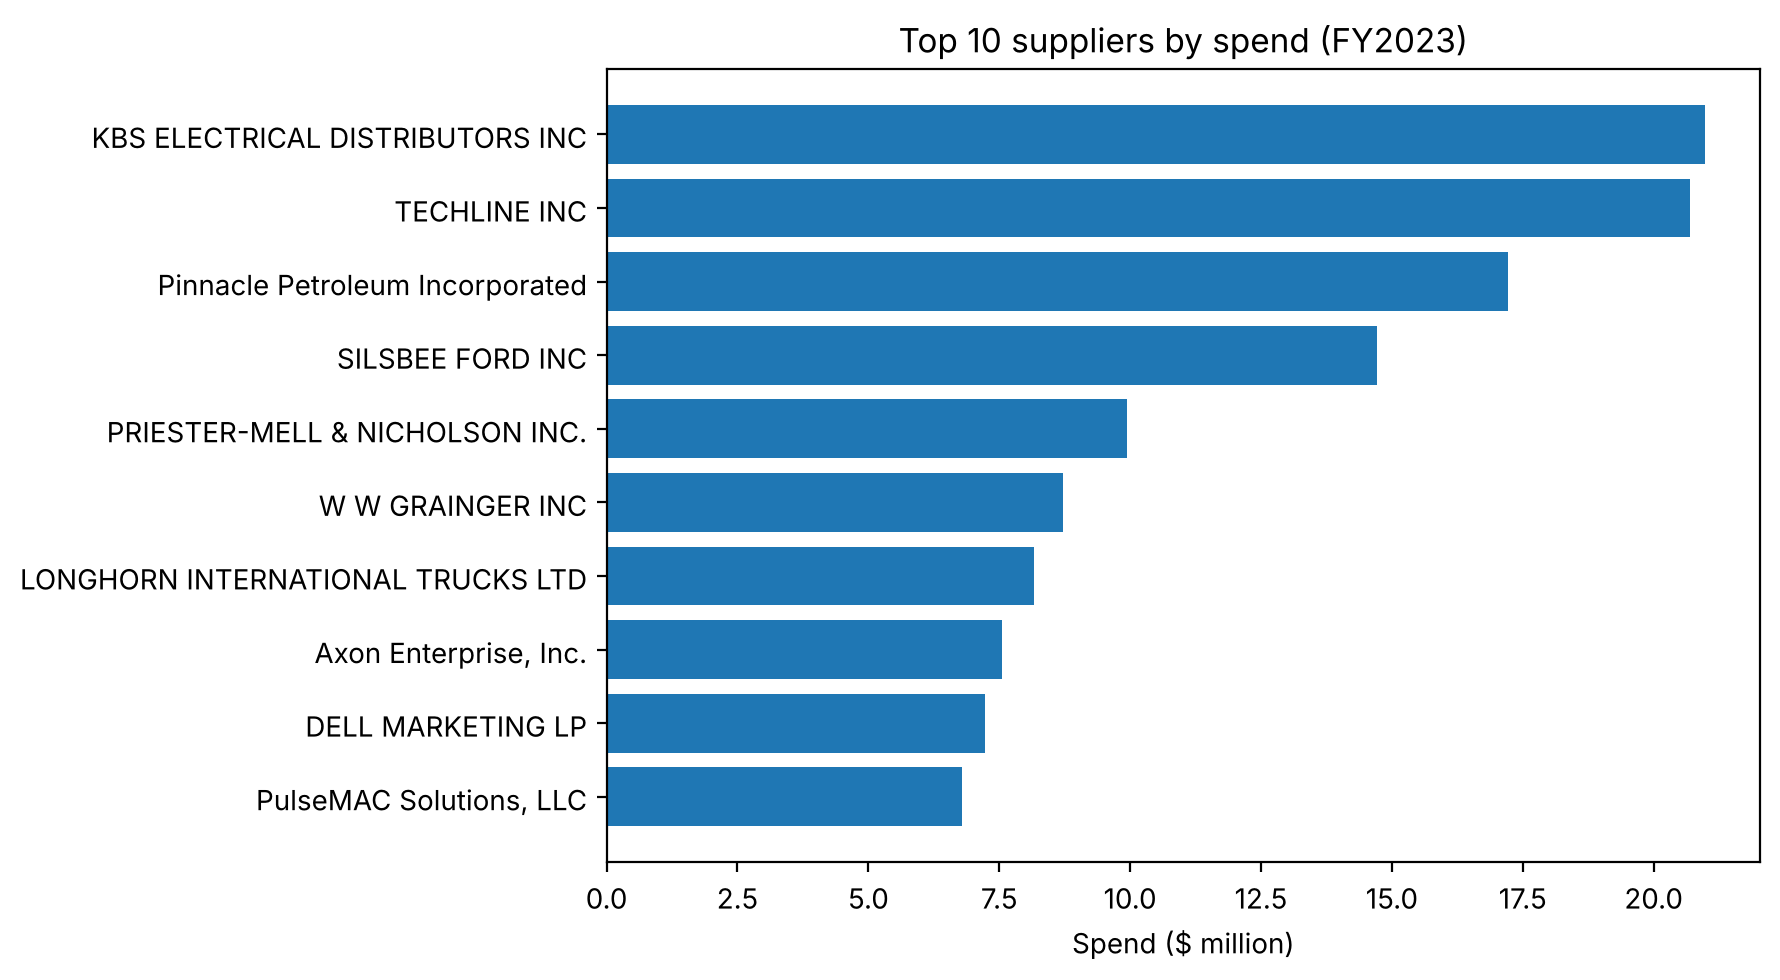

In [11]:
top10 = vendor_spend.head(10)

plt.figure(figsize=(9, 5))
plt.barh(top10["vendor"], top10["spend"] / 1_000_000)
plt.gca().invert_yaxis()   # largest supplier on top
plt.xlabel("Spend ($ million)")
plt.title("Top 10 suppliers by spend (FY2023)")
plt.tight_layout()
plt.savefig("images/top10_suppliers.png", dpi=150)
plt.show()

**Result:**
- Of 916 suppliers, the top 10 receive **37.4%** of total spend.
- **80% of spend goes to 78 suppliers**, only **8.5%** of all suppliers.
- Even the largest supplier (KBS Electrical, electrical supplies) receives just 6.4% of the total. There is no heavy dependence on a single supplier.

**Interpretation:** Spend is clearly concentrated (few suppliers, large share), but not locked into any single supplier. A sensible focus for the procurement team is the 78 suppliers that make up 80% of spend.

## 6. Question 2: Is there a spending spike at fiscal year-end?

**Why it matters:** A common expectation for public bodies is that spending rises towards year-end so that unspent budget is not lost. Austin's fiscal year **starts in October and ends in September**. If the expectation holds, there should be a rise in September.

**Method:** Sum spend by month and compare it with the monthly average.

In [12]:
monthly = df.groupby("month")["itm_tot_am"].sum() / 1_000_000   # $ million
monthly_avg = monthly.mean()

print("Monthly average ($ million):", round(monthly_avg, 1))
monthly.round(1)

Monthly average ($ million): 27.2


month
2022-10   76.00
2022-11   22.00
2022-12   18.70
2023-01   25.40
2023-02   21.10
2023-03   30.50
2023-04   17.30
2023-05   20.20
2023-06   27.70
2023-07   16.50
2023-08   35.10
2023-09   15.80
Freq: M, Name: itm_tot_am, dtype: float64

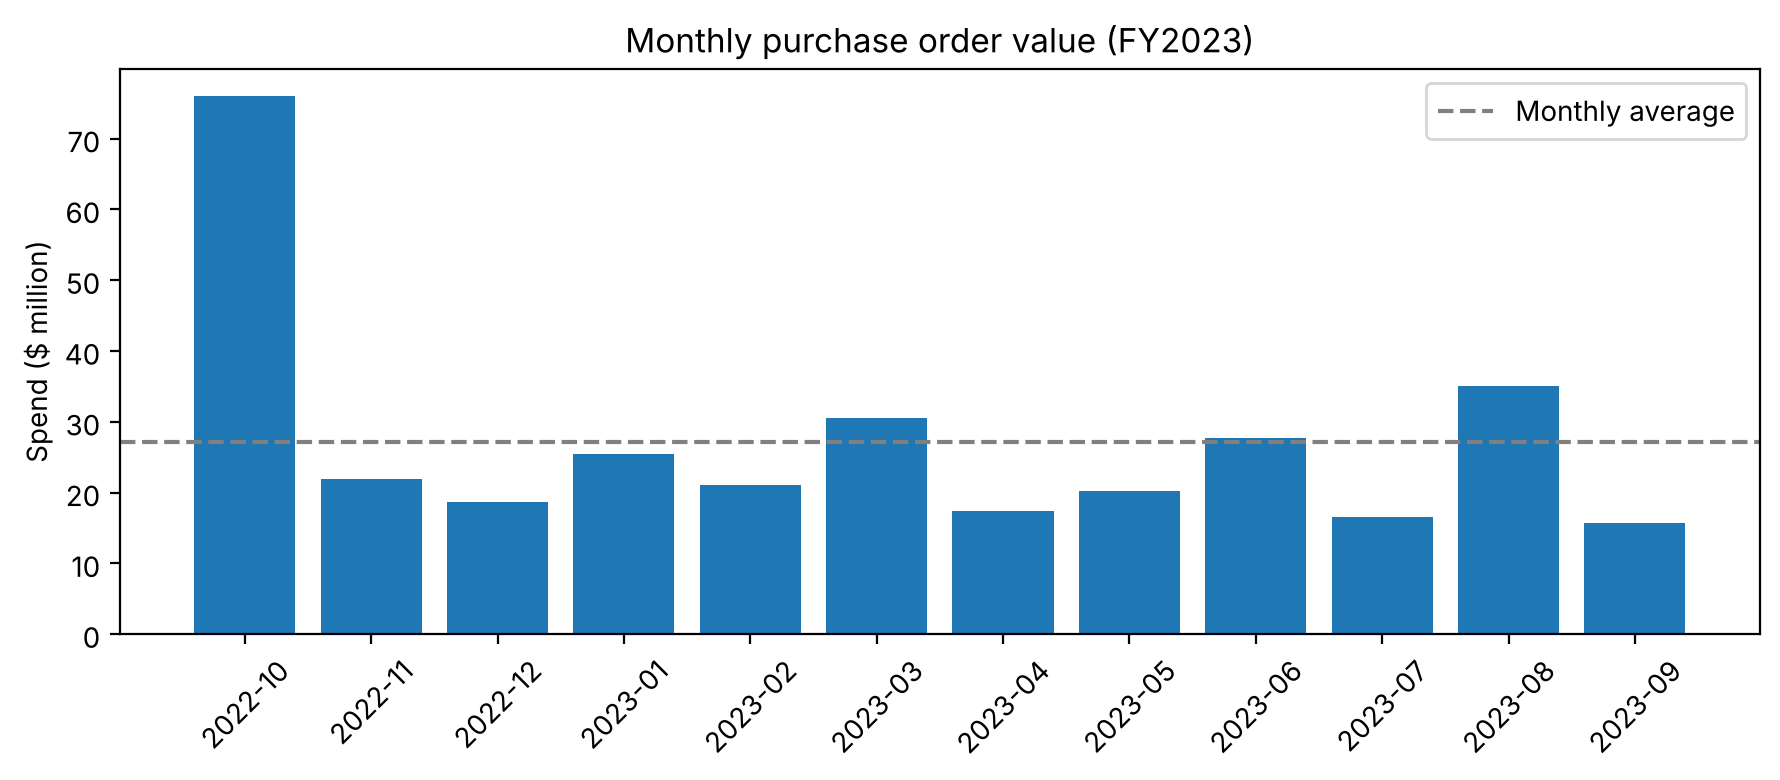

In [13]:
plt.figure(figsize=(9, 4))
plt.bar(monthly.index.astype(str), monthly.values)
plt.axhline(monthly_avg, color="gray", linestyle="--", label="Monthly average")
plt.xticks(rotation=45)
plt.ylabel("Spend ($ million)")
plt.title("Monthly purchase order value (FY2023)")
plt.legend()
plt.tight_layout()
plt.savefig("images/monthly_spend.png", dpi=150)
plt.show()

The opposite of the expectation: **September is the lowest month of the year**, while the highest is **October**, the first month of the fiscal year. To understand why October is so high, let's look at its 10 largest line items.

In [14]:
october = df[df["award_date"].dt.month == 10]
october_top10 = october.nlargest(10, "itm_tot_am")

print("October total ($ million):", round(october["itm_tot_am"].sum() / 1_000_000, 1))
print("Share of the 10 largest line items in October (%):",
      round(october_top10["itm_tot_am"].sum() / october["itm_tot_am"].sum() * 100, 1))

october_top10[["award_date", "lgl_nm", "contract_name", "itm_tot_am"]]

October total ($ million): 76.0
Share of the 10 largest line items in October (%): 36.2


,award_date,lgl_nm,contract_name,itm_tot_am
27,2022-10-01,W W GRAINGER INC,Blanket DO for ProCard Purchases FY23 Grainger,"6,155,888.00"
276,2022-10-05,Asphalt Inc LLC,SBO Various Units/Hot Mix/FY23 Contract Card E...,"5,250,000.00"
239,2022-10-04,"LHOIST NORTH AMERICA OF TEXAS, LLC",Quicklime,"2,419,638.08"
294,2022-10-06,ERGON ASPHALT & EMULSIONS INC,Contract Card / Ergon FY23,"2,100,000.00"
290,2022-10-05,YOUNGBLOOD AUTOMOTIVE & TIRE LLC,Tires and Tubes & Associated Components,"2,084,582.08"
1028,2022-10-27,METRO FIRE APPARATUS SPECIALISTS INC,FY23 - METRO FIRE,"2,016,489.32"
23,2022-10-01,MATERA PAPER COMPANY INC,Blanket DO for ProCard Purchases FY23 Ferguson...,"1,995,090.41"
28,2022-10-01,HOME DEPOT USA INC,Blanket DO for ProCard Purchases FY23 The Home...,"1,932,000.00"
1075,2022-10-28,SILSBEE FORD INC,FY23-SILSBEE FORD,"1,871,307.48"
1072,2022-10-28,SILSBEE FORD INC,FY23-SILSBEE FORD,"1,737,642.66"


**Result:**
- **October** is the highest month at $76.0M: 23% of total spend in a single month, about 2.8 times the monthly average ($27.2M).
- **September** is the lowest month at $15.8M. The expected year-end spike does not appear in this data.
- The contract names of October's largest line items include phrases such as *Blanket DO for ProCard Purchases FY23*, *FY23 Contract Card Encumbrance* and *FY23 - METRO FIRE*. These are **orders opened at the start of the year to be used throughout the year**. The 10 largest line items alone make up 36% of October.

**Interpretation:** This data shows **when an order was placed**, not when money was paid. Because annual orders are opened at the start of the year, order value piles up in October. Testing for a year-end spending spike would require payment data, not order data.

## 7. Question 3: How much of the spend is tied to master agreements?

**Why it matters:** A master agreement means prices and terms were negotiated in advance. Spend outside agreements (called *maverick spend* in procurement) is usually less controlled and can be more expensive.

**Method:** If the `master_agreement` column is filled in, the line item is tied to a master agreement.

In [15]:
df["has_master_agreement"] = df["master_agreement"].notna()

coverage = df.groupby("has_master_agreement")["itm_tot_am"].agg(["count", "sum"])
coverage["sum"] = coverage["sum"] / 1_000_000                       # $ million
coverage["share_pct"] = coverage["sum"] / coverage["sum"].sum() * 100
coverage

,count,sum,share_pct
has_master_agreement,,,
False,2207,22.23,6.81
True,8492,304.04,93.19


Which product categories account for most of the spend not tied to a master agreement?

In [16]:
no_ma = df[df["master_agreement"].isna()]

no_ma_by_category = (
    no_ma.groupby("commodity_description")["itm_tot_am"].sum()
         .sort_values(ascending=False)
         / 1_000_000
)
no_ma_by_category.head(10).round(2)

commodity_description
HELICOPTERS                                                    3.08
Industrial and Construction Machinery, Equipment, Components   2.69
LIME, QUICK                                                    2.42
Equipment and Supplies, Helicopter                             2.25
Engines and Parts, Helicopter                                  0.80
Police Investigation Robots                                    0.60
Ready-Mix Concrete                                             0.39
LIGHTING SYSTEMS, THEATER                                      0.26
SIMULATORS, TRAINING                                           0.19
BEARINGS, ROLLER, TAPERED (TIMKEN OR EQUAL)                    0.17
Name: itm_tot_am, dtype: float64

**Result:**
- **93.2%** of spend ($304.0M) is tied to master agreements.
- The 2,207 line items not tied to an agreement make up 21% of rows but only **6.8%** of spend ($22.2M).
- The largest items outside agreements are helicopters ($3.1M), industrial machinery ($2.7M) and quicklime ($2.4M).

**Interpretation:** Agreement coverage is high. What falls outside is mostly **one-off, large capital purchases** such as helicopters and machinery, which one would expect to be bought through a separate contract or tender. Confirming this would require checking the order types with the purchasing department.

## 8. Limitations

1. **Order date, not payment:** `award_date` is the date the order was placed. It does not show when money was paid.
2. **Not all of the city's procurement:** As its name says, the dataset focuses on goods (commodity) purchases. It does not show the city's total procurement spend.
3. **One fiscal year:** The results cover FY2023 only. Several years would need to be compared to see whether the October spike repeats every year.
4. **Prices for the same product cannot be compared.** The reason is shown below.

**Why was there no price comparison for the same product?**

An obvious question would be "Is the city paying different suppliers different prices for the same product?" But the `commodity` code identifies a **product group**, not a single product. Take the code for distribution transformers (`28586`):

In [17]:
transformers = df[(df["commodity"] == "28586") & (df["quantity"] > 0)]

print("Rows:", len(transformers))
print("Suppliers:", transformers["vendor_code"].nunique())
transformers["unit_price"].agg(["min", "median", "max"])

Rows: 402
Suppliers: 7


min          459.00
median     6,600.00
max      229,425.00
Name: unit_price, dtype: float64

Under the same code, the unit price ranges from $459 to $229,425. Let's look at the descriptions of the cheapest and the most expensive line items:

In [18]:
cheapest = transformers.nsmallest(1, "unit_price")
dearest = transformers.nlargest(1, "unit_price")

print("Cheapest:", cheapest["unit_price"].iloc[0], "$")
print(cheapest["extended_description"].iloc[0][:110])
print()
print("Most expensive:", dearest["unit_price"].iloc[0], "$")
print(dearest["extended_description"].iloc[0][:110])

Cheapest: 459.0 $
TRANSFORMER, REFURBISHED, DISTRIBUTION, SINGLE PHASE, POLE MOUNT 25 KVA, 120/240 VOLT, 3 WIRE, 2 HV BUSHINGS, 

Most expensive: 229425.0 $
TRANSFORMER, NETWORK, 3-PHASE, 2000KVA, 34.5KV, 480Y/277 VOLTS IN  ACCORDANCE WITH LATEST REVISION OF SPECIFIC


The cheapest is a refurbished, single-phase, 25 kVA pole-mounted transformer. The most expensive is a new three-phase, 2000 kVA network transformer. Both share a code but are completely different products, so the price gap does not mean the city overpaid for the same item. A real price comparison would need a product-level identifier (e.g. the manufacturer part number).

**Noticing that the data cannot answer a question, and saying so, is part of the analysis too.**

## 9. Summary

| Question | Finding |
|---|---|
| Supplier concentration | The top 10 suppliers receive 37.4% of spend. 80% of spend goes to 78 of 916 suppliers (8.5%). |
| Year-end spike | None. September is the lowest month. The real spike is in October (23%), driven by annual orders opened at the start of the year. |
| Master agreement coverage | 93.2% of spend is tied to master agreements. Spend outside agreements is concentrated in one-off large purchases. |

## 10. Try it yourself

Use the methods in this notebook to answer these questions on your own:

1. Repeat Question 1 by product category (`commodity_description`) instead of supplier: which 10 categories have the highest spend?
2. How much of the spend goes to suppliers outside Texas? (Use the `st` column and watch out for missing values.)
3. What does the monthly distribution look like without October? Is there a clear difference between the remaining months?